# Getting started with `fem_1d`

This notebook builds one problem from scratch and opens up every stage, so you
can see what each piece of the package does and what it holds:

1. **Mesh**: where the elements are
2. **Space**: which functions a field may take, and how they are stored
3. **Weak form**: the equation written as a list of `Term`s
4. **Problem**: assembling the matrix and applying boundary conditions
5. **Solve**: the forward solution, and reactions at the boundaries
6. **Adjoint**: one extra solve that tells you how a quantity responds to loads
7. **Kernel**: the sensitivity of that quantity to a model parameter
8. **Several fields**: one space per field, coupled by terms

The running example is a string with tension $\mu(x) = 1 + x$ under a uniform
load, fixed at both ends:

$$
-\big(\mu\,u'\big)' = 1 \quad\text{on } [0, 1], \qquad u(0) = u(1) = 0,
$$

whose exact solution is $u(x) = \ln(1+x)/\ln 2 - x$.

In [1]:
import matplotlib.pyplot as plt
import numpy as np

import fem_1d as fem
from fem_1d.plotting import plot_basis, plot_kernel, plot_mesh

np.set_printoptions(precision=4, suppress=True, linewidth=110)

mu = lambda x: 1 + x
u_exact = lambda x: np.log1p(x) / np.log(2) - x
du_exact = lambda x: (1 / np.log(2) - 1 - x) / (1 + x)

## 1. Mesh

A `Mesh` is only the element end points. It knows nothing about polynomial
degree or fields, so several fields can share it.

In [2]:
mesh = fem.uniform_mesh(1.0, 2)  # 2 equal elements on [0, 1]
print("end points xe:", mesh.xe)
print("lengths he:   ", mesh.he)

end points xe: [0.  0.5 1. ]
lengths he:    [0.5 0.5]


For radial problems you would usually use `sized_mesh`, which pins interfaces
(e.g. the 660 km discontinuity) to element boundaries and limits the element
width:

In [3]:
mantle = fem.sized_mesh(
    [0.546, 0.896, 1.0], drmax=0.06
)  # CMB, 660, surface in planet radii
print(mantle.n_elements, "elements; end points:", mantle.xe)

8 elements; end points: [0.546  0.6043 0.6627 0.721  0.7793 0.8377 0.896  0.948  1.    ]


## 2. Space: one per field

A `FunctionSpace` says which functions a field may take. Ours is

$$
V_h = \{u \text{ continuous on } [0,1],\ \text{a polynomial of degree} \le 2 \text{ on each element}\}.
$$

It is built from the mesh, a polynomial degree, and whether the field may jump
between elements. **Every field you solve for gets its own space**; fields with
the same degree and continuity can share one.

In [4]:
space = fem.FunctionSpace.build(mesh, 2)
print("dof coordinates x:", space.x)
print("connectivity conn:", space.conn.tolist())
print("number of dofs:   ", space.n_dofs)

dof coordinates x: [0.   0.25 0.5  0.75 1.  ]
connectivity conn: [[0, 1, 2], [2, 3, 4]]
number of dofs:    5


Each element has the 3 Gauss–Lobatto–Legendre (GLL) nodes of the reference
element $[-1, 1]$, mapped onto it. `conn[e]` lists the global dofs of element
`e`: element 0 owns dofs 0–2 and element 1 owns dofs 2–4, so **they share dof 2**
at $x = 0.5$. That shared number is the only thing that makes the field
continuous.

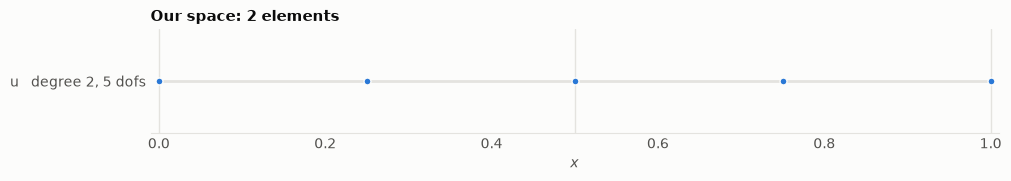

In [5]:
plot_mesh(space, title="Our space");

Every element looks the same on the reference element: a set of Lagrange basis
functions, each 1 at its own node and 0 at the others, plus the quadrature
weights used for every integral.

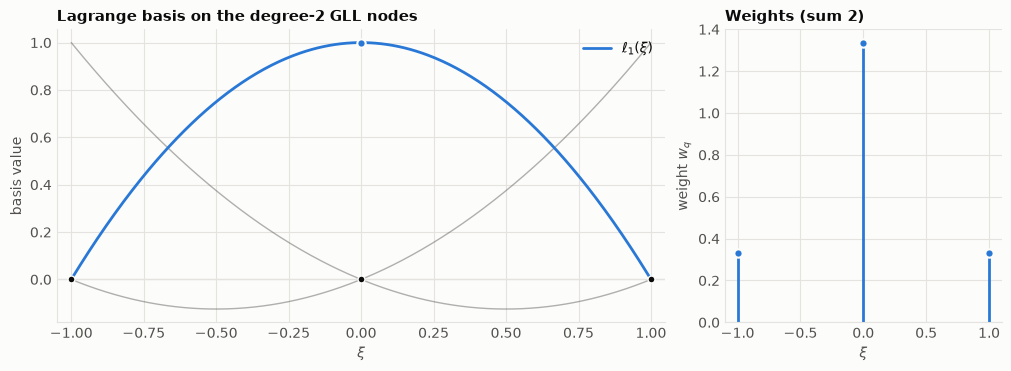

In [6]:
fig = plot_basis(fem.reference_element(2), highlight=1)
plt.show()

**A function in the space is just its nodal values.** Given the 5 numbers,
`evaluate` reconstructs $u(x) = \sum_j u_j\,\varphi_j(x)$ anywhere. The value is
continuous at $x = 0.5$, but the derivative is not: it has a kink at each
element boundary, so `evaluate` lets you choose which side with `side=`.

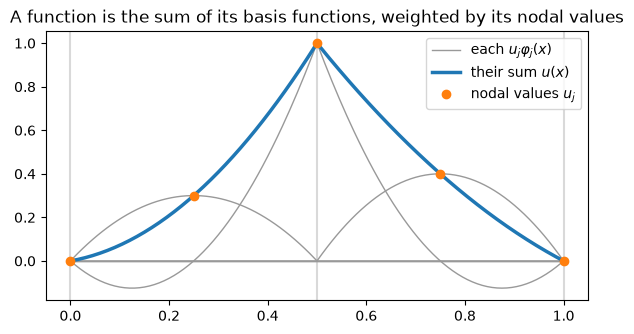

u'(0.5) from below: [3.6]
u'(0.5) from above: [-2.8]


In [7]:
u_example = np.array([0.0, 0.3, 1.0, 0.4, 0.0])
xx = np.linspace(0, 1, 201)

fig, ax = plt.subplots(figsize=(7, 3.5))
for j in range(space.n_dofs):
    e = np.zeros(space.n_dofs)
    e[j] = 1
    ax.plot(
        xx,
        u_example[j] * space.evaluate(e, xx),
        lw=1,
        color="0.6",
        label="each $u_j \\varphi_j(x)$" if j == 1 else None,
    )
ax.plot(xx, space.evaluate(u_example, xx), lw=2.5, label="their sum $u(x)$")
ax.plot(space.x, u_example, "o", label="nodal values $u_j$")
for x in mesh.xe:
    ax.axvline(x, color="0.85", zorder=0)
ax.legend()
ax.set_title(
    "A function is the sum of its basis functions, weighted by its nodal values"
)
plt.show()

print("u'(0.5) from below:", space.evaluate(u_example, 0.5, d=1, side="below"))
print("u'(0.5) from above:", space.evaluate(u_example, 0.5, d=1, side="above"))

With `discontinuous=True`, each element gets its own end dofs, so $x = 0.5$ has
two dofs and the field may jump there. That is what a pressure field needs where
the viscosity jumps.

In [8]:
broken = fem.FunctionSpace.build(mesh, 2, discontinuous=True)
print("conn:", broken.conn.tolist(), "  x:", broken.x)

conn: [[0, 1, 2], [3, 4, 5]]   x: [0.   0.25 0.5  0.5  0.75 1.  ]


## 3. The weak form, as terms

Multiply the equation by a test function $v$ that vanishes at the fixed ends,
integrate, and integrate by parts:

$$
\underbrace{\int_0^1 \mu\,u'\,v'\,dx}_{a(u,\,v)} \;=\; \underbrace{\int_0^1 1\cdot v\,dx}_{\ell(v)} .
$$

Each integral becomes one object:

- `Term(coeff, d_test, d_trial)` is $\int \text{coeff}(x)\; \partial^{d_\text{trial}} u\; \partial^{d_\text{test}} v\,dx$;
- `LoadTerm(f)` is $\int f(x)\, v\,dx$.

We write $\mu$ as a **named parameter** (`param="mu"`) rather than inside the
coefficient. The matrix is the same either way, but the name lets
`Problem.kernel` find the terms that depend on $\mu$ later.

In [9]:
terms = [fem.Term(lambda x: 1.0, d_test=1, d_trial=1, param="mu")]  # ∫ μ u' v'
loads = [fem.LoadTerm(lambda x: 1.0)]  # ∫ 1 · v
constraints = [
    fem.Dirichlet("u", "left"),
    fem.Dirichlet("u", "right"),
]  # u(0) = u(1) = 0
params = {"mu": mu}

## 4. `Problem`: assembly and constraints

Creating a `Problem` assembles the matrix $A$ and load vector $\mathbf b$ once,
and turns the `Dirichlet` conditions into a list of fixed dofs. Nothing is solved
yet.

In [10]:
problem = fem.Problem(space, terms, loads, constraints, params)

print("A =\n", problem.A.toarray())
print("b =", problem.b)
print("fixed dofs:", problem.fixed, "  free mask:", problem.free.astype(int))

{'u': slice(0, 5, None)}
hello
A =
 [[  5.1667  -6.       0.8333   0.       0.    ]
 [ -6.      13.3333  -7.3333   0.       0.    ]
 [  0.8333  -7.3333  14.      -8.6667   1.1667]
 [  0.       0.      -8.6667  18.6667 -10.    ]
 [  0.       0.       1.1667 -10.       8.8333]]
b = [0.0833 0.3333 0.1667 0.3333 0.0833]
fixed dofs: [0 4]   free mask: [0 1 1 1 0]


In [25]:
from scipy import sparse
from fem_1d.assembly import (
    _as_spaces,
    _quadrature,
    _with_param,
    _scatter,
    dof_slices,
    element_matrix,
)

spaces = _as_spaces(space)  # one space → {"u": space}
slices = dof_slices(spaces)  # {"u": slice(0, 5)}: one field, so offset 0
quad = _quadrature(spaces)  # GLL rule of degree 2
t = terms[0]
coeff = _with_param(t.coeff, t.param, params)  # 1.0 × mu(x)
Ae = element_matrix(space, space, coeff, t.d_test, t.d_trial, quad)
print("Ae shape:", Ae.shape)  # (2 elements, 3 test, 3 trial)

offset = slices["u"].start
r, c, v = _scatter(Ae, space.conn + offset, space.conn + offset)
print("conn:", space.conn.tolist())
for row, col, val in zip(r, c, v):
    print(f"({row},{col})  {val:8.4f}")

Ae shape: (4, 4, 4)
conn: [[0, 1, 2, 3], [3, 4, 5, 6], [6, 7, 8, 9], [9, 10, 11, 12]]
(0,0)   17.8333
(0,1)  -20.1879
(0,2)    3.1045
(0,3)   -0.7500
(1,0)  -20.1879
(1,1)   35.6366
(1,2)  -18.7500
(1,3)    3.3012
(2,0)    3.1045
(2,1)  -18.7500
(2,2)   39.3634
(2,3)  -23.7179
(3,0)   -0.7500
(3,1)    3.3012
(3,2)  -23.7179
(3,3)   21.1667
(3,3)   22.1667
(3,4)  -25.0663
(3,5)    3.8163
(3,6)   -0.9167
(4,3)  -25.0663
(4,4)   43.9699
(4,5)  -22.9167
(4,6)    4.0130
(5,3)    3.8163
(5,4)  -22.9167
(5,5)   47.6967
(5,6)  -28.5963
(6,3)   -0.9167
(6,4)    4.0130
(6,5)  -28.5963
(6,6)   25.5000
(6,6)   26.5000
(6,7)  -29.9447
(6,8)    4.5280
(6,9)   -1.0833
(7,6)  -29.9447
(7,7)   52.3033
(7,8)  -27.0833
(7,9)    4.7247
(8,6)    4.5280
(8,7)  -27.0833
(8,8)   56.0301
(8,9)  -33.4747
(9,6)   -1.0833
(9,7)    4.7247
(9,8)  -33.4747
(9,9)   29.8333
(9,9)   30.8333
(9,10)  -34.8231
(9,11)    5.2398
(9,12)   -1.2500
(10,9)  -34.8231
(10,10)   60.6366
(10,11)  -31.2500
(10,12)    5.4365
(11,9)  

$A$ is built element by element. For element $e$ of length $h_e$, with GLL
weights $w_q$ and derivative matrix $D_{qk} = \varphi_k'(\xi_q)$,

$$
A^e_{kl} = \frac{2}{h_e}\sum_q w_q\,\mu(x_q)\,D_{qk}\,D_{ql},
$$

and the element matrices are **added** into $A$ at the rows and columns
`conn[e]`. They overlap only at the shared dof 2:

In [11]:
from fem_1d.assembly import element_matrix

Ke = element_matrix(space, space, lambda x: 1.0 * mu(x), d_test=1, d_trial=1)
print("element 0:\n", Ke[0])
print("element 1:\n", Ke[1])
print(f"A[2,2] = {Ke[0][2, 2]:.4f} + {Ke[1][0, 0]:.4f} = {problem.A[2, 2]:.4f}")
print(
    "row sums of A (a constant stores no energy):",
    problem.A.toarray().sum(axis=1),
)

element 0:
 [[ 5.1667 -6.      0.8333]
 [-6.     13.3333 -7.3333]
 [ 0.8333 -7.3333  6.5   ]]
element 1:
 [[  7.5     -8.6667   1.1667]
 [ -8.6667  18.6667 -10.    ]
 [  1.1667 -10.       8.8333]]
A[2,2] = 6.5000 + 7.5000 = 14.0000
row sums of A (a constant stores no energy): [-0.  0. -0. -0.  0.]


## 5. Solve

The fixed dofs are known, so only the free rows are solved:

$$
A_{ff}\,\mathbf u_f = \mathbf b_f - A_{fd}\,\mathbf u_d .
$$

`solve()` factorises $A_{ff}$ once (and keeps the factors) and returns a
`Solution`. Here is the same thing by hand, for comparison:

In [12]:
sol = problem.solve()

f, d = problem.free, problem.fixed
A = problem.A.toarray()
u_by_hand = np.zeros(space.n_dofs)
u_by_hand[f] = np.linalg.solve(A[np.ix_(f, f)], problem.b[f])

print("solve():    ", sol["u"])
print("by hand:    ", u_by_hand)
print("exact nodes:", u_exact(space.x))

solve():     [0.     0.0717 0.0849 0.0573 0.    ]
by hand:     [0.     0.0717 0.0849 0.0573 0.    ]
exact nodes: [0.     0.0719 0.085  0.0574 0.    ]


Two elements of degree 2 are already within about $10^{-3}$. Refining the
mesh or raising the degree converges quickly. Here is a finer problem (4
elements of degree 3), which we use from now on:

{'u': slice(0, 13, None)}
hello


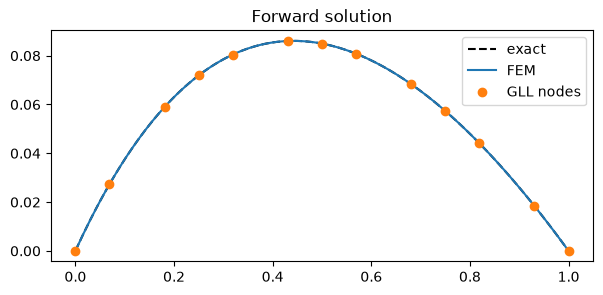

max error between nodes: 1.1026267545843904e-05


In [13]:
def string_problem(mu, n=3, Ne=4):
    space = fem.FunctionSpace.build(fem.uniform_mesh(1.0, Ne), n)
    return fem.Problem(space, terms, loads, constraints, params={"mu": mu})


problem = string_problem(mu)
space = problem.spaces["u"]
sol = problem.solve()

fig, ax = plt.subplots(figsize=(7, 3))
ax.plot(xx, u_exact(xx), "k--", label="exact")
ax.plot(xx, sol.evaluate("u", xx), label="FEM")
ax.plot(space.x, sol["u"], "o", label="GLL nodes")
ax.legend()
ax.set_title("Forward solution")
plt.show()
print(
    "max error between nodes:",
    np.abs(sol.evaluate("u", xx) - u_exact(xx)).max(),
)

### Reactions

The fixed rows were left out of the solve. Their residual $(A\mathbf u - \mathbf b)_i$
is the force needed to hold that dof fixed: the boundary term
$[\mu u' v]_0^1$ dropped when integrating by parts. So `reaction` returns the
outward flux, $-\mu u'(0)$ at the left and $+\mu u'(1)$ at the right, without
differentiating the solution. For Stokes, the same thing gives the normal
stress, and so the dynamic topography.

In [14]:
print(
    "reaction left: ",
    sol.reaction("u", "left"),
    "  exact -mu u'(0):",
    -mu(0) * du_exact(0),
)
print(
    "reaction right:",
    sol.reaction("u", "right"),
    "  exact  mu u'(1):",
    mu(1) * du_exact(1),
)
print("residual (zero at free dofs):", sol.residual())

reaction left:  -0.4426950682540738   exact -mu u'(0): -0.4426950408889634
reaction right: -0.557304931745926   exact  mu u'(1): -0.5573049591110366
residual (zero at free dofs): [-0.4427 -0.     -0.     -0.      0.     -0.      0.     -0.     -0.      0.      0.      0.     -0.5573]


## 6. Adjoint

Pick a quantity of interest: the midpoint deflection $J = u(0.5)$. As a vector
of weights on the dofs, $J = \mathbf c\cdot\mathbf u$, and `functional` builds
$\mathbf c$ for any point, node or not.

The **adjoint** solves $A^{\mathsf T}\boldsymbol\lambda = \mathbf c$, with the
same factors as the forward solve. Then $J = \boldsymbol\lambda\cdot\mathbf b$, so
$\lambda_i$ is how much $J$ changes per unit of load at dof $i$. For the string,
$\lambda$ is the deflection under a unit point force at $x = 0.5$: the Green's
function.

J = c·u = 0.08496249429942511    λ·b = 0.08496249429942512


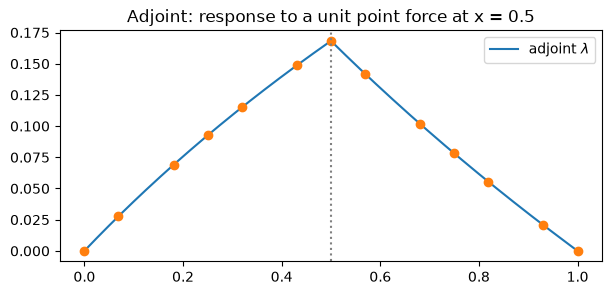

In [15]:
c = problem.functional("u", 0.5)
lam = problem.adjoint(c)

print("J = c·u =", c @ sol.u, "   λ·b =", lam @ problem.b)

fig, ax = plt.subplots(figsize=(7, 3))
ax.plot(xx, space.evaluate(lam, xx), label="adjoint $\\lambda$")
ax.plot(space.x, lam, "o")
ax.axvline(0.5, color="0.5", ls=":")
ax.legend()
ax.set_title("Adjoint: response to a unit point force at x = 0.5")
plt.show()

## 7. Sensitivity kernel

How does $J$ change if the tension changes by $\delta\mu(x)$? Perturbing
$A\mathbf u = \mathbf b$ and using the adjoint gives

$$
\delta J = -\boldsymbol\lambda^{\mathsf T}\,\delta A\,\mathbf u
         = \int_0^1 K(x)\,\delta\mu(x)\,dx,
\qquad K(x) = -\lambda'(x)\,u'(x).
$$

`kernel("mu", c=...)` finds the terms tagged `"mu"`, does one forward and one
adjoint solve, and evaluates $-\lambda' u'$ at the quadrature points. Because
$\lambda'$ jumps at the observation point, so does the kernel.

In [16]:
x0 = 0.5
C1 = 1 - np.log1p(x0) / np.log(2)
K_exact = lambda x: -(np.where(x < x0, C1, C1 - 1) / mu(x)) * du_exact(x)

K = problem.kernel("mu", c=problem.functional("u", x0))
plot_kernel(K, exact=K_exact, label="$-\\lambda' u'$");

`K.apply(dmu)` predicts the change in $J$ for a perturbation $\delta\mu$. Here it
is next to the actual change from re-solving with the perturbed tension. They
differ by the second-order term, which shrinks like $\delta\mu^2$:

In [17]:
J = lambda m: string_problem(m).solve().evaluate("u", x0)[0]
bump = lambda x: np.exp(-(((x - 0.3) / 0.1) ** 2))

for size in (1e-2, 1e-3, 1e-4):
    dmu = lambda x: size * bump(x)
    predicted = K.apply(dmu)
    actual = J(lambda x: mu(x) + dmu(x)) - J(mu)
    print(
        f"size {size:.0e}: predicted {predicted:.6e}   actual {actual:.6e}   relative gap {abs(predicted - actual) / abs(actual):.1e}"
    )

{'u': slice(0, 13, None)}
hello
{'u': slice(0, 13, None)}
hello
size 1e-02: predicted -6.707361e-05   actual -6.682498e-05   relative gap 3.7e-03
{'u': slice(0, 13, None)}
hello
{'u': slice(0, 13, None)}
hello
size 1e-03: predicted -6.707361e-06   actual -6.704864e-06   relative gap 3.7e-04
{'u': slice(0, 13, None)}
hello
{'u': slice(0, 13, None)}
hello
size 1e-04: predicted -6.707361e-07   actual -6.707111e-07   relative gap 3.7e-05


## 8. Several fields: one space per field

A coupled problem has a space for each field, all on one mesh. The fields are
stacked into one global vector, and `dof_slices` says where each one sits.
Terms name the fields they couple with `test=` and `trial=`.

As an example, write $-u'' = f$ as a first-order system, with a **continuous** flux
$\sigma = u'$ and a **discontinuous** $u$, the same continuous/discontinuous
pairing as velocity and pressure in Stokes:

$$
\int \sigma\,\tau\,dx + \int u\,\tau'\,dx = 0, \qquad
-\int \sigma'\,v\,dx = \int f\,v\,dx .
$$

The boundary values $u(0) = u(1) = 0$ enter through the boundary term
$[u\,\tau]_0^1$, which vanishes, so there are no `Dirichlet` conditions at all.

In [18]:
mesh = fem.uniform_mesh(1.0, 4)
spaces = {
    "sigma": fem.FunctionSpace.build(mesh, 4),  # continuous, degree 4
    "u": fem.FunctionSpace.build(
        mesh, 3, discontinuous=True
    ),  # discontinuous, degree 3
}
one = lambda x: 1.0
mixed_terms = [
    fem.Term(one, 0, 0, test="sigma", trial="sigma"),  # ∫ σ τ
    fem.Term(one, 1, 0, test="sigma", trial="u"),  # ∫ u τ'
    fem.Term(lambda x: -1.0, 0, 1, test="u", trial="sigma"),  # -∫ σ' v
]
f_load = lambda x: np.pi**2 * np.sin(np.pi * x)
mixed = fem.Problem(spaces, mixed_terms, [fem.LoadTerm(f_load, test="u")])

print("dof slices:", mixed.slices)
plot_mesh(spaces, title="Two fields on one mesh");

{'sigma': slice(0, 17, None), 'u': slice(17, 33, None)}
hello
dof slices: {'sigma': slice(0, 17, None), 'u': slice(17, 33, None)}


The global matrix has a block for each pair of fields. Its pattern shows which
fields couple: the $\sigma\sigma$ block is the mass matrix, the off-diagonal
blocks are the two coupling terms, and the $uu$ block is empty.

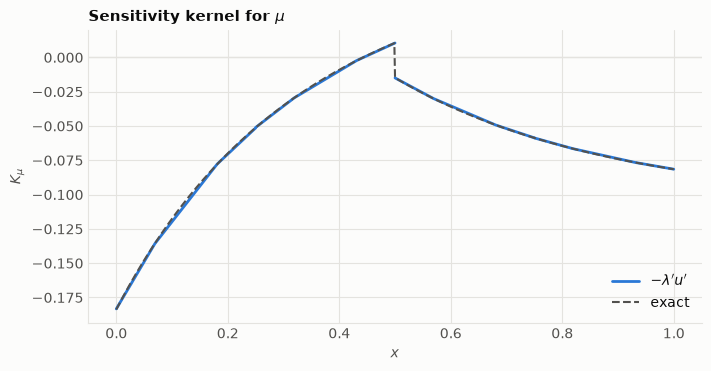

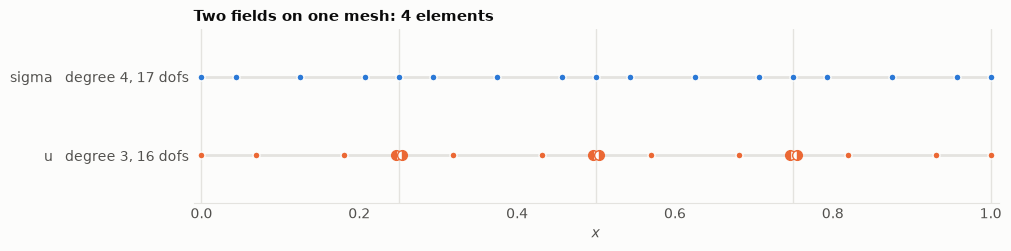

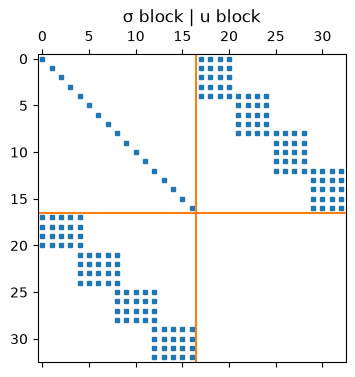

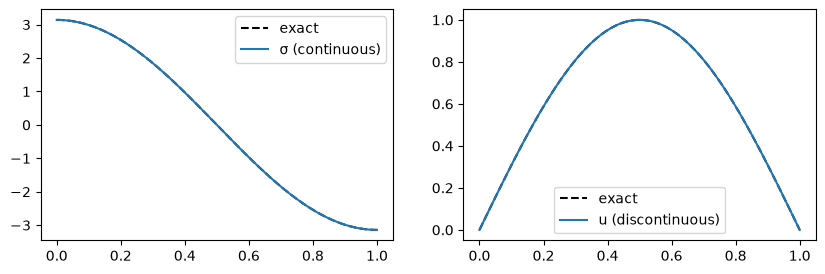

In [19]:
fig, ax = plt.subplots(figsize=(4, 4))
ax.spy(mixed.A.toarray(), markersize=3)
n_sigma = spaces["sigma"].n_dofs
ax.axhline(n_sigma - 0.5, color="C1")
ax.axvline(n_sigma - 0.5, color="C1")
ax.set_title("σ block | u block")
plt.show()

msol = mixed.solve()
fig, axes = plt.subplots(1, 2, figsize=(10, 3))
axes[0].plot(xx, np.pi * np.cos(np.pi * xx), "k--", label="exact")
axes[0].plot(xx, msol.evaluate("sigma", xx), label="σ (continuous)")
axes[1].plot(xx, np.sin(np.pi * xx), "k--", label="exact")
for e in range(mesh.n_elements):  # draw u element by element: it may jump
    xe = np.linspace(mesh.xe[e], mesh.xe[e + 1], 30)
    axes[1].plot(
        xe,
        msol.evaluate("u", xe, side="below" if e else "above"),
        color="C0",
        label="u (discontinuous)" if e == 0 else None,
    )
for ax in axes:
    ax.legend()
plt.show()

## Summary

| Stage | Object | What it holds or does |
|---|---|---|
| Mesh | `Mesh`, `sized_mesh` | element end points, shared by all fields |
| Space | `FunctionSpace`, one per field | degree, continuity, dof numbering (`conn`), node coordinates |
| Weak form | `Term`, `LoadTerm`, `PointTerm`, `PointLoad` | each integral (or point term), with optional `param` tags |
| Boundary conditions | `Dirichlet` | fixed values; natural conditions go in the weak form |
| Problem | `Problem` | assembles $A$, $\mathbf b$; `solve`, `adjoint`, `kernel` on one cached factorisation |
| Results | `Solution`, `Kernel` | fields, `evaluate`, `reaction`; kernel values and `apply` |

**Things to try**

- Change $\mu$ to a two-layer model, `np.where(x < 0.4, 1.0, 5.0)`, with a mesh
  from `fem.sized_mesh([0, 0.4, 1], drmax=0.25)`, and look at the kernel at the
  interface.
- Take the kernel of the right-end reaction instead:
  `problem.kernel("mu", r=problem.functional("u", "right"))`.
- Use `relative=True` to get the kernel with respect to $\ln\mu$.